# Homework 8. Человек и человекоподобный гуманоид

**Выполнил:** Сидоров, РИС-24-1-1. **Язык реализации:** Python.

Положительный класс (1) — обычный человек. Отрицательный (0) — человекоподобный двуногий робот или костюм робота. Люди в гриме, рисунки, рендеры и схемы исключены. Для классификации по согласованию используются кадрированные фотографии объектов обоих классов. Для детектора сохраняются целые сцены с людьми.

Базовый набор: 100 людей + 100 гуманоидов. Отдельный тест детектора: ещё 50 людей + 50 гуманоидов. Источники: [Penn–Fudan](https://www.cis.upenn.edu/~jshi/ped_html/) и реальные снимки камер [B-Human](https://b-human.informatik.uni-bremen.de/public/datasets/robots/), согласованные вместо ограничившего доступ Wikimedia. Отобраны стоящие двуногие роботы NAO и другие роботы гуманоидной лиги; лежащие роботы исключены. Это более узкий отрицательный класс, чем все возможные фантастические персонажи. Полные источники кадров сохранены в манифестах. Рамки людей получены из исходных масок Penn–Fudan и проверены визуально с разрешения пользователя. Это не полностью новая ручная разметка.

Зависимости: `%pip install -r requirements.txt`. Запускайте ячейки сверху вниз из папки работы. Модели обучаются здесь заново; готовый детектор людей не используется.

## 1.1. Данные и разбиение

Сначала фиксируем исходные фотографии, затем делим базовый набор 80/20 со стратификацией. Получаются 160 обучающих и 40 тестовых примеров, поровну по классам. Аугментации выполняются только после разбиения и только на train. Отдельные 100 изображений детектора не используются для обучения и настройки параметров.

Всего фотографий: 300
Классы в базовом наборе: {0: 100, 1: 100}
Train: 160 Test: 40


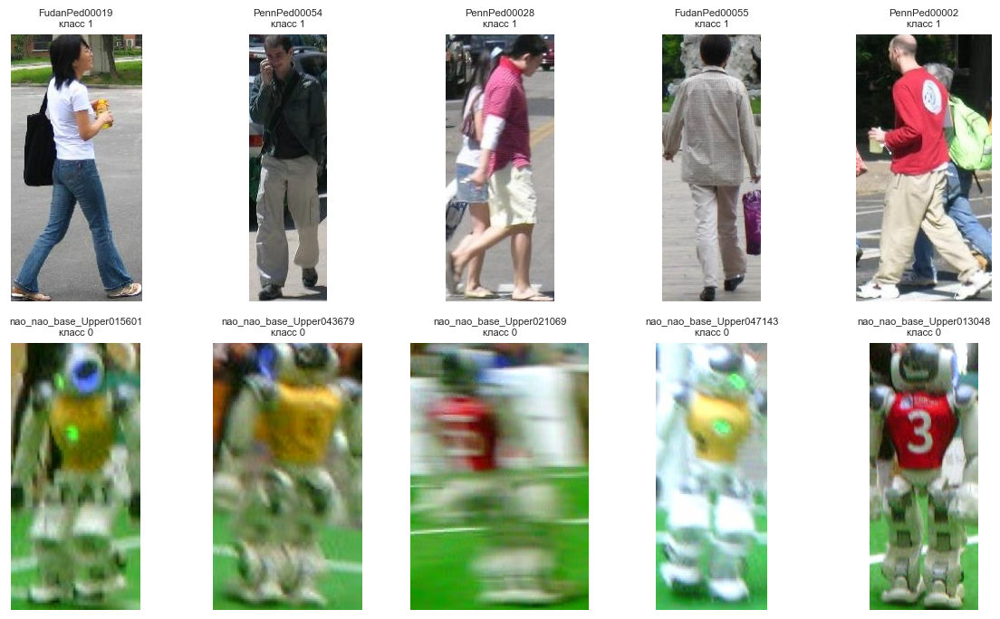

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from hog_lab import read_photo, feature, models, augment, fit_detector, detect, match_boxes, iou, HOG_OPTIONS

sns.set_theme(style="whitegrid")
people = json.loads(Path("people_manifest.json").read_text(encoding="utf-8"))
robots = json.loads(Path("robots_manifest.json").read_text(encoding="utf-8"))
base = [r for r in people + robots if r["split"] == "base"]
holdout = [r for r in people + robots if r["split"] == "detector_test"]
assert len(base) == 200 and len(holdout) == 100
assert sum(r["label"] for r in base)==100 and sum(r["label"] for r in holdout)==50
assert not ({r["id"] for r in base} & {r["id"] for r in holdout})
y = np.array([r["label"] for r in base])
train_idx, test_idx = train_test_split(np.arange(200),test_size=0.2,stratify=y,random_state=42)
pd.DataFrame([{**r,"subset":"train" if i in train_idx else "test"} for i,r in enumerate(base)]).to_json("classification_split.json",orient="records",force_ascii=False,indent=2)
print("Всего фотографий:",len(base)+len(holdout))
print("Классы в базовом наборе:",dict(zip(*np.unique(y,return_counts=True))))
print("Train:",len(train_idx),"Test:",len(test_idx))
fig,axes=plt.subplots(2,5,figsize=(12,7))
for ax,row in zip(axes.flat,[*base[:5],*base[100:105]]):
    ax.imshow(read_photo(row["crop"]))
    ax.set_title(f'{row["id"]}\nкласс {row["label"]}',fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

**Интерпретация примеров.** На фотографиях обоих классов видны голова, туловище и конечности, поэтому общая форма схожа. У людей разнообразны одежда и направление движения; на кадрах роботов часто заметны сочленения, округлые головы и смазывание движения. Эти снимки получены из разных источников: фон, резкость и разрешение могут быть побочными признаками класса. Кадры роботов не являются рисунками или синтетическими рендерами.

## 1.2. HOG и таблица признаков

Приводим область объекта к 64×128 пикселям и оттенкам серого. HOG строит гистограммы направлений градиента: 9 направлений на ячейку 8×8, нормализация L2-Hys в блоках 2×2. Получаем 7×15×2×2×9 = 3780 признаков. Исходный путь, вектор целиком и класс сохраняются в таблицу `hog_features.csv`, числовая матрица — в `hog_features.npz`.

,image,HOG,class
0,images/people_crops/FudanPed00019.jpg,"[0.13714970648288727, 0.05378098785877228, 0.0...",1
1,images/people_crops/PennPed00054.jpg,"[0.05924828350543976, 0.0, 0.04148295894265175...",1
2,images/people_crops/PennPed00028.jpg,"[0.24974872171878815, 0.24974872171878815, 0.2...",1
3,images/people_crops/FudanPed00055.jpg,"[0.1170879378914833, 0.028581272810697556, 0.0...",1
4,images/people_crops/PennPed00002.jpg,"[0.21668091416358948, 0.06252246350049973, 0.1...",1


Размер матрицы: (200, 3780)


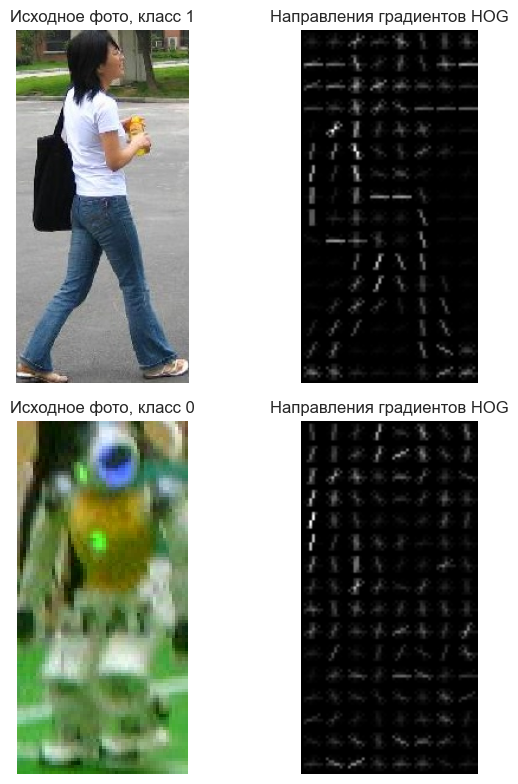

In [2]:
X=np.asarray([feature(read_photo(r["crop"])) for r in base])
assert X.shape==(200,3780) and np.isfinite(X).all()
hog_table=pd.DataFrame({"image":[r["crop"] for r in base],"HOG":[json.dumps(v.tolist()) for v in X],"class":y})
hog_table.to_csv("hog_features.csv",index=False)
np.savez_compressed("hog_features.npz",X=X,y=y,train_idx=train_idx,test_idx=test_idx)
display(hog_table.head())
print("Размер матрицы:",X.shape)
fig,axes=plt.subplots(2,2,figsize=(7,8))
for row_axes,row in zip(axes,[base[0],base[100]]):
    image=read_photo(row["crop"])
    _,picture=feature(image,visualize=True)
    row_axes[0].imshow(image); row_axes[0].set_title(f'Исходное фото, класс {row["label"]}')
    row_axes[1].imshow(picture,cmap="gray"); row_axes[1].set_title("Направления градиентов HOG")
    for ax in row_axes: ax.axis("off")
plt.tight_layout();plt.show()

**Интерпретация HOG.** Светлые штрихи справа показывают локальные направления выраженных изменений яркости. У человека видны контуры ног, одежды и сумки, у робота — головы, корпуса и сочленений. HOG сохраняет форму через градиенты, но непосредственно не кодирует исходный цвет. Из-за приведения к 64×128 и смазывания мелкие детали могут потеряться. Для обоих классов получается один и тот же размер вектора — 3780, что позволяет подавать их в три классических классификатора.

## 1.3–1.4. Три классификатора и визуальный разбор

Обучаем kNN, линейный SVM и Logistic Regression. Масштабирование признаков входит в pipeline и обучается только на train. Основная метрика — Accuracy; F1, Precision и Recall показывают распознавание класса «человек». После таблицы просматриваем весь тест: для каждого снимка указаны правильный и предсказанный классы, ошибки выделены красным.

,Accuracy,F1,Precision,Recall
Модель,,,,
kNN,0.85,0.824,1.0,0.7
SVM,1.00,1.000,1.0,1.0
Logistic Regression,1.00,1.000,1.0,1.0


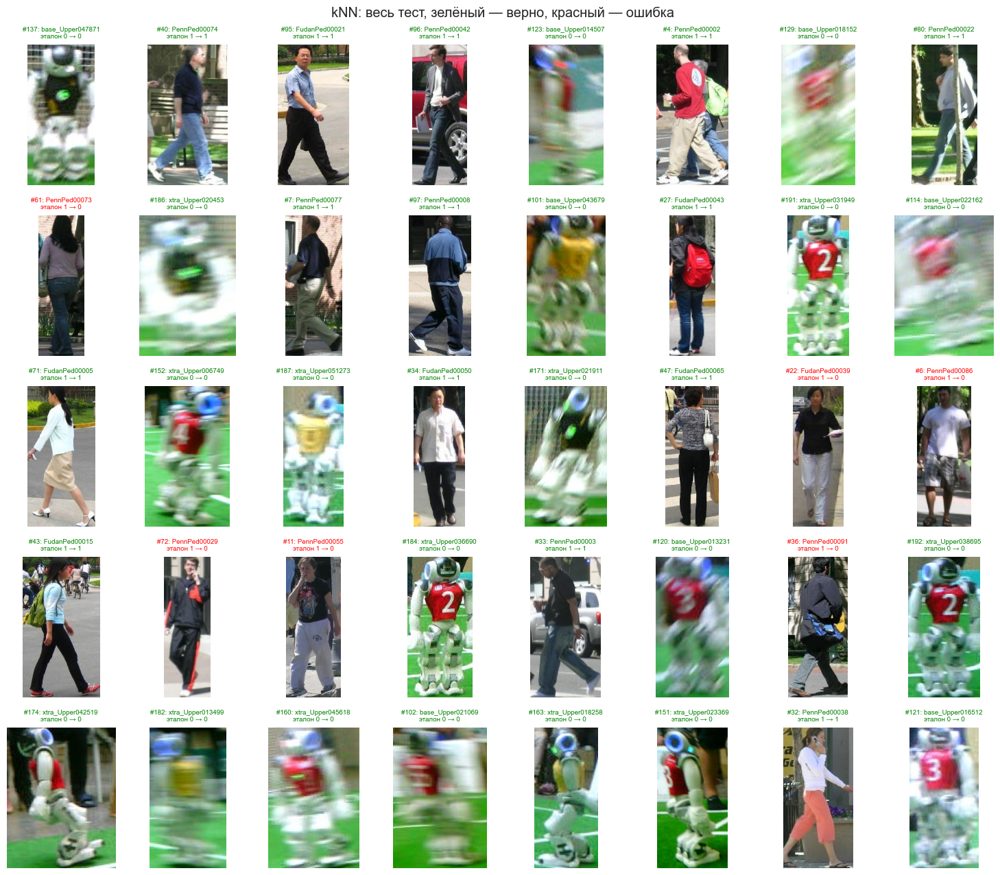

kNN ошибки: ['PennPed00073', 'FudanPed00039', 'PennPed00086', 'PennPed00029', 'PennPed00055', 'PennPed00091']


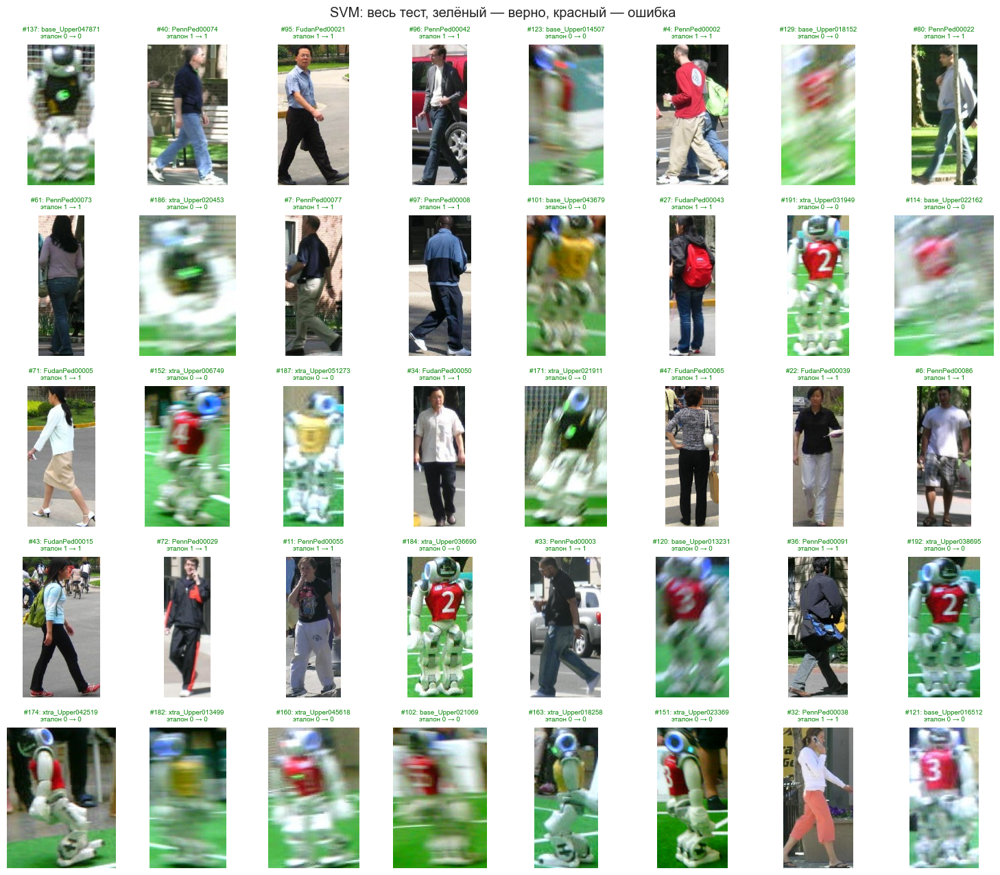

SVM ошибки: []


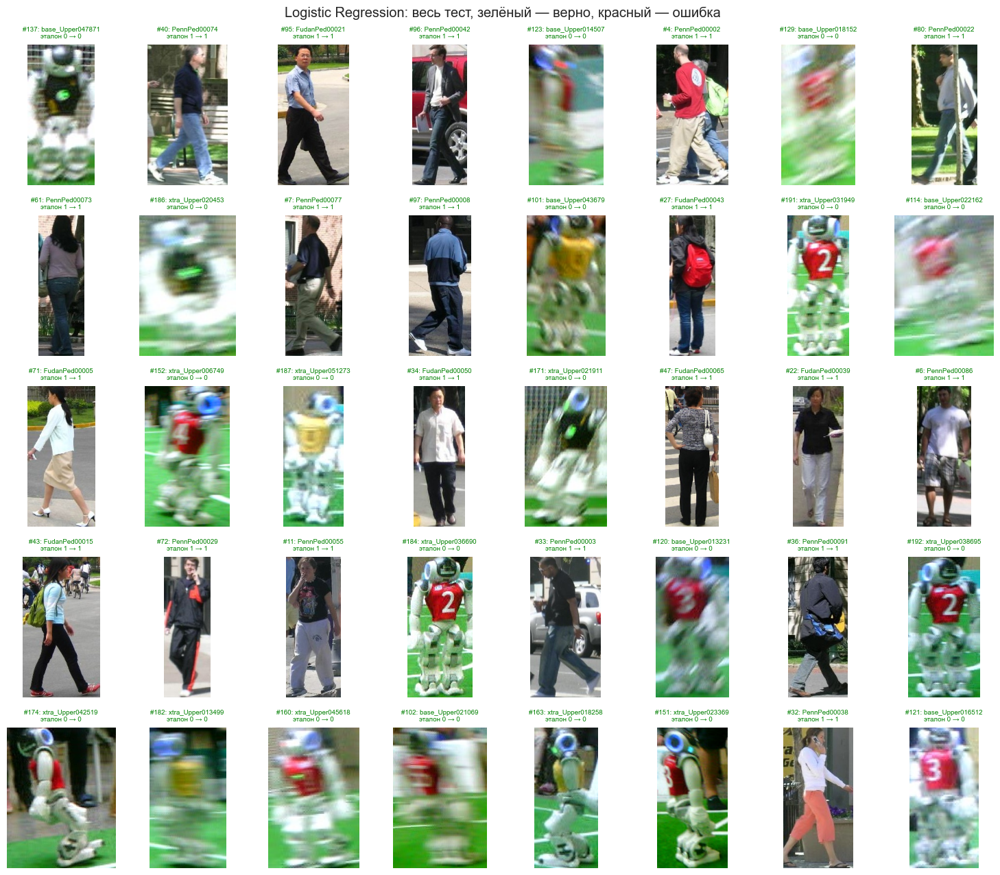

Logistic Regression ошибки: []


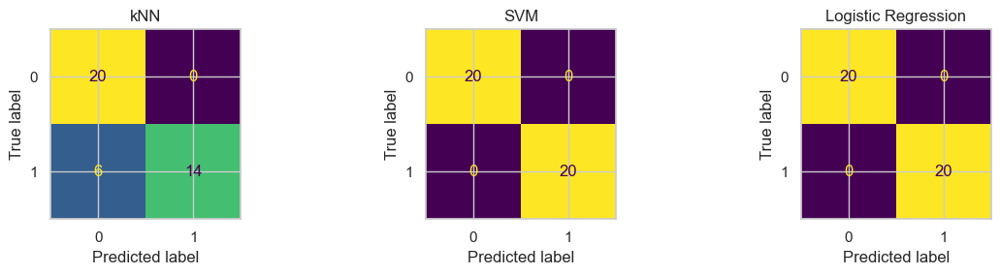

In [3]:
def classification_row(name,model,data):
    prediction=model.predict(data)
    return {"Модель":name,"Accuracy":accuracy_score(y[test_idx],prediction),"F1":f1_score(y[test_idx],prediction),
            "Precision":precision_score(y[test_idx],prediction,zero_division=0),"Recall":recall_score(y[test_idx],prediction,zero_division=0)},prediction

fitted,predictions,rows={},{},[]
for name,model in models().items():
    fitted[name]=model.fit(X[train_idx],y[train_idx])
    row,predictions[name]=classification_row(name,model,X[test_idx]); rows.append(row)
baseline=pd.DataFrame(rows).set_index("Модель")
display(baseline.round(3))
for name in fitted:
    fig,axes=plt.subplots(5,8,figsize=(15,13))
    for ax,index,guess in zip(axes.flat,test_idx,predictions[name]):
        row=base[index]; ax.imshow(read_photo(row["crop"]));ax.axis("off")
        ax.set_title(f'#{index}: {row["id"][-16:]}\nэталон {y[index]} → {guess}',fontsize=7,color="green" if y[index]==guess else "red")
    fig.suptitle(f"{name}: весь тест, зелёный — верно, красный — ошибка")
    plt.tight_layout();plt.show()
    errors=[base[index]["id"] for index,guess in zip(test_idx,predictions[name]) if guess!=y[index]]
    print(name,"ошибки:",errors)
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,name in zip(axes,fitted):
    ConfusionMatrixDisplay.from_predictions(y[test_idx],predictions[name],ax=ax,colorbar=False)
    ax.set_title(name)
plt.tight_layout();plt.show()

**Интерпретация классификации и всех трёх галерей.** kNN распознал 34 из 40 фотографий, то есть Accuracy = 0.850. Все шесть ошибок — люди, ошибочно отнесённые к гуманоидам. Среди них PennPed00073 (вид со спины), FudanPed00039 и PennPed00086 (фронтальные виды), PennPed00029, PennPed00055 и PennPed00091. На этих кадрах общий силуэт относительно прямой; HOG-расстояние без понимания семантики может сблизить его с силуэтом двуногого робота. Это визуальное объяснение ошибки, а не измеренная причинная связь.

На матрице kNN: 20/20 гуманоидов распознаны правильно, а среди людей верно только 14/20. Поэтому Precision класса «человек» равна 1.0, но Recall только 0.7, F1 = 0.824. SVM и Logistic Regression на всех 40 снимках дали правильные классы, что видно и на галереях, и на диагональных матрицах ошибок. По этой проверке они делят первое место; назвать один из них точнее другого нельзя. Для небольшого набора кадрированных объектов линейная разделяющая граница оказалась удачнее локального поиска соседей.

**Ограничение.** Роботы базового набора сняты в одном матче с двух камер, а люди — в городских сценах Penn–Fudan. Близкие кадры одного источника могут попадать в train и test; проверка SHA-256 исключает точные копии, но не все похожие сцены. Поэтому 100% здесь не означает универсального распознавания любых людей и гуманоидов. В независимом тесте детектора используются кадры другого матча.

## Дополнительная часть +1: аугментация

На базовом тесте kNN ошибочно отнёс шесть людей к гуманоидам, включая фронтальные виды и виды со спины с относительно прямым силуэтом. У объектов общие вертикальные контуры и расположение конечностей. Кроме того, кадры роботов заметно более смазаны, чем фотографии людей; источник съёмки может быть нежелательной подсказкой классу. Добавим только к train горизонтальное отражение, повороты на ±7°, уменьшение яркости до 75 % и слабое гауссово размытие (радиус 0.7). Класс сохраняется. Эти преобразования проверяют вариативность позы и освещения и уменьшают привязку к резкости. Это попытка улучшения, а не гарантия роста метрик. Новые оригиналы после просмотра теста не добавляем; тест и параметры моделей остаются теми же.

Размер train после аугментации: (960, 3780)


,Accuracy до,F1 до,Precision до,Recall до,Accuracy после,F1 после,Precision после,Recall после
Модель,,,,,,,,
kNN,0.85,0.824,1.0,0.7,0.925,0.919,1.0,0.85
SVM,1.00,1.000,1.0,1.0,1.000,1.000,1.0,1.00
Logistic Regression,1.00,1.000,1.0,1.0,1.000,1.000,1.0,1.00


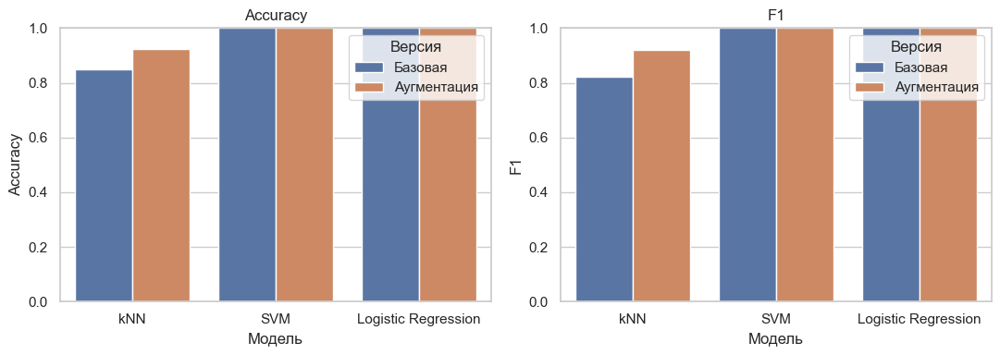

In [4]:
aug_X=[X[train_idx]];aug_y=[y[train_idx]]
for index in train_idx:
    generated=augment(read_photo(base[index]["crop"]))
    aug_X.append(np.asarray([feature(image) for image in generated]))
    aug_y.append(np.repeat(y[index],len(generated)))
aug_X=np.vstack(aug_X);aug_y=np.concatenate(aug_y)
print("Размер train после аугментации:",aug_X.shape)
augmented_rows=[]
for name,model in models().items():
    model.fit(aug_X,aug_y)
    row,_=classification_row(name,model,X[test_idx]);augmented_rows.append(row)
augmented=pd.DataFrame(augmented_rows).set_index("Модель")
comparison=baseline.add_suffix(" до").join(augmented.add_suffix(" после"))
display(comparison.round(3))
plot=pd.concat([baseline.assign(Версия="Базовая"),augmented.assign(Версия="Аугментация")]).reset_index()
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric in zip(axes,["Accuracy","F1"]):
    sns.barplot(data=plot,x="Модель",y=metric,hue="Версия",ax=ax)
    ax.set_ylim(0,1);ax.set_title(metric)
plt.tight_layout();plt.show()

**Интерпретация улучшений.** Добавление пяти преобразований к каждому обучающему примеру увеличило train со 160 до 960 HOG-векторов. Тест остался прежним: 40 исходных снимков. Accuracy kNN выросла с 0.850 до 0.925 (34 → 37 правильных ответов), F1 — с 0.824 до 0.919, Recall людей — с 0.700 до 0.850. Precision сохранилась равной 1.0. Значит, неверно распознанных людей стало три вместо шести, а дополнительных ложных распознаваний гуманоидов как людей не появилось. Это согласуется с гипотезой о пользе вариативности направления, позы и качества снимка для поиска соседей.

Для SVM и Logistic Regression обе диаграммы остаются на уровне 1.000: их исходный тест уже был распознан без ошибок, поэтому на этой выборке улучшать Accuracy было некуда. Отдельный вклад каждого преобразования не измерялся. Аугментация выбрана после просмотра ошибок базового теста, как требует задание; его повторный результат является сравнением на тех же примерах, а не новой независимой оценкой обобщения.

## Дополнительная часть +2: собственный детектор HOG + линейный SVM

Следуем архитектуре [Далала и Триггса](https://lear.inrialpes.fr/people/triggs/pubs/Dalal-cvpr05.pdf): HOG + линейный SVM, скользящее окно и пирамида масштабов. Это учебная реализация общей схемы, а не побитовое воспроизведение оригинального кода статьи. Обучаем по рамкам из 100 базовых сцен с людьми, отрицательным фоновым окнам только из этих сцен и 100 базовым гуманоидам.

На пирамиде с коэффициентом 1.25 используем окно 64×128, шаг 8 пикселей, порог SVM 0 и подавление перекрывающихся рамок NMS при IoU > 0.3. Эти параметры фиксируются до теста. Проверяем 100 новых фотографий: 50 сцен с людьми и 50 областей гуманоидов без людей. В исходном Penn–Fudan некоторые мелкие или сильно перекрытые люди не размечены; оценка проводится относительно предоставленных размеченных экземпляров, что ограничивает полноту эталона.

IoU = площадь пересечения / площадь объединения предсказанной и эталонной рамок. Правильное обнаружение требует IoU≥0.5 и однозначного сопоставления. Дополнительно отдельно считаем классификацию целого снимка по наличию хотя бы одной рамки. Для изображения без людей IoU не определяем; там оцениваются ложные срабатывания. При отсутствии предсказания для размеченного человека его лучший IoU равен 0.

HOG-окон для обучения детектора по классам: {0: 622, 1: 486}


Проверено изображений: 10


Проверено изображений: 20


Проверено изображений: 30


Проверено изображений: 40


Проверено изображений: 50


... (2 outputs left out)

Проверено изображений: 80


Проверено изображений: 90


Проверено изображений: 100


,Accuracy наличия,Precision рамок,Recall рамок,Средний лучший IoU,TP рамок,FP рамок,FN рамок
0,0.72,0.093,0.843,0.6,107,1040,20


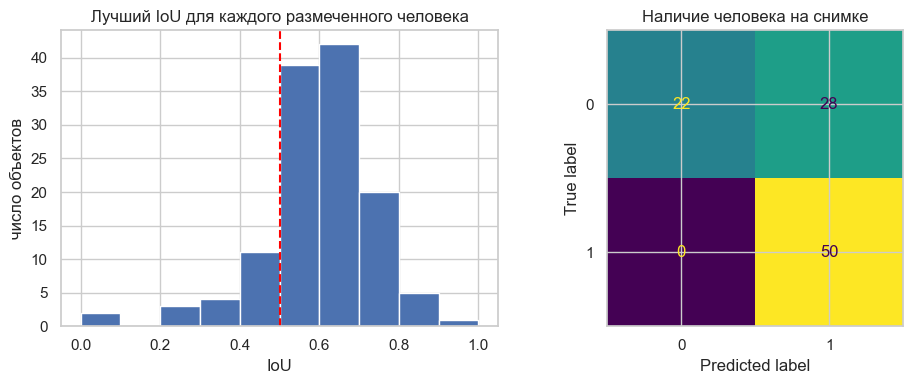

,id,class,TP,FP,FN
0,PennPed00049,1,4,19,0
1,FudanPed00013,1,1,16,0
2,PennPed00050,1,1,15,0
3,PennPed00048,1,3,21,0
4,PennPed00046,1,2,18,1
...,...,...,...,...,...
95,nao_nao_test_Upper039249,0,0,0,0
96,nao_nao_test_Upper027519,0,0,1,0
97,nao_nao_test_Upper036367,0,0,1,0
98,nao_nao_test_Upper025048,0,0,1,0


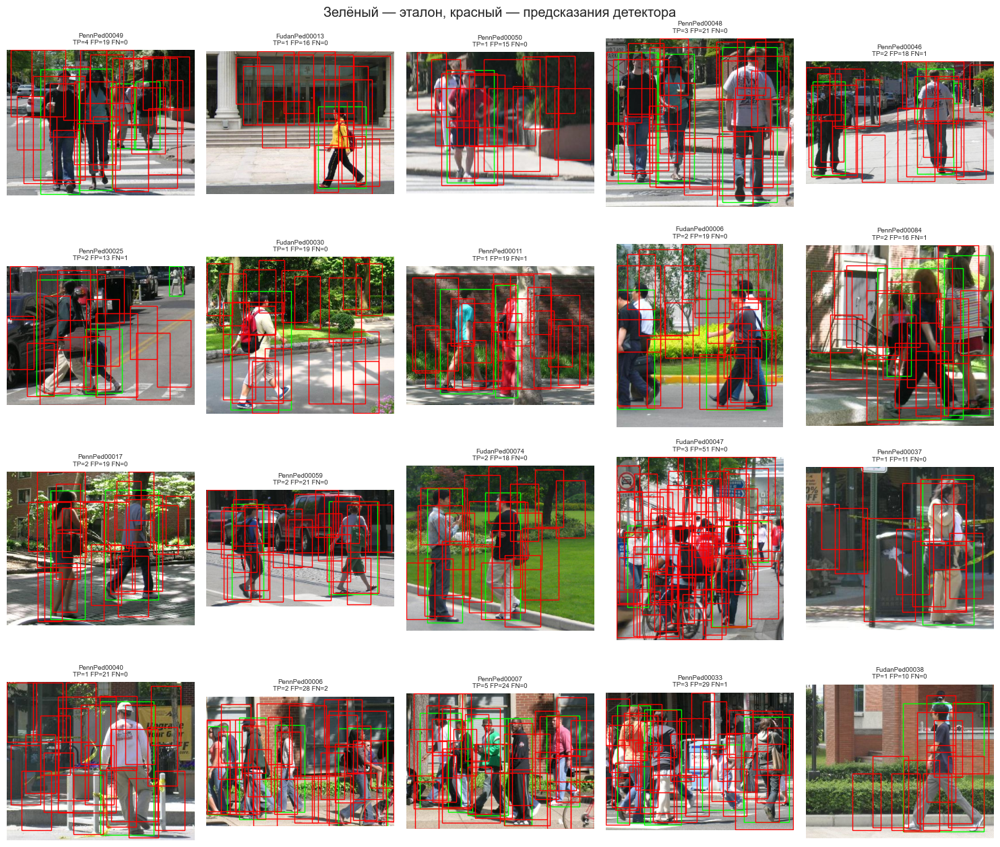

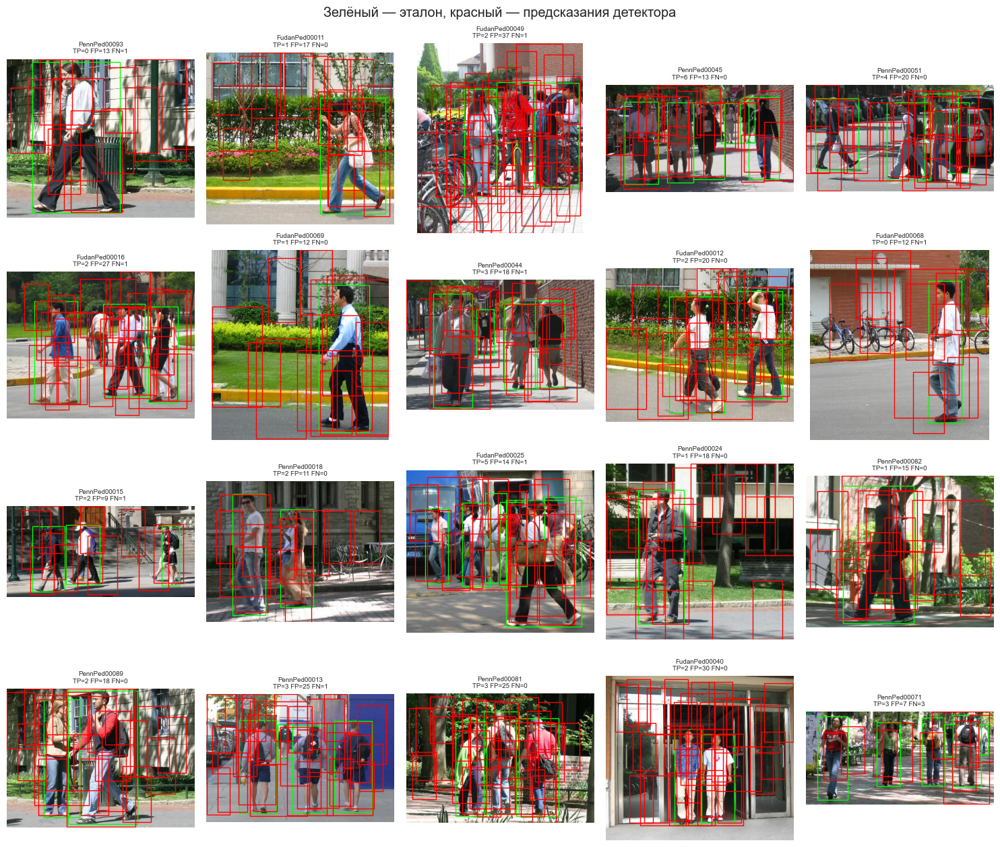

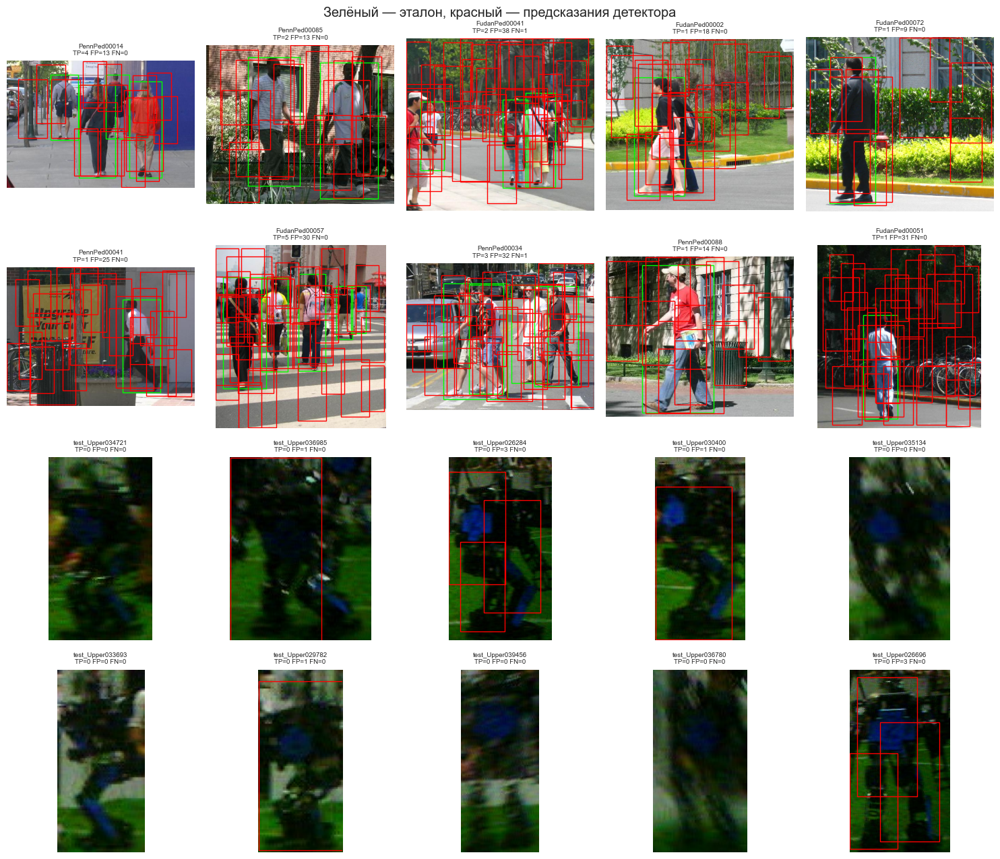

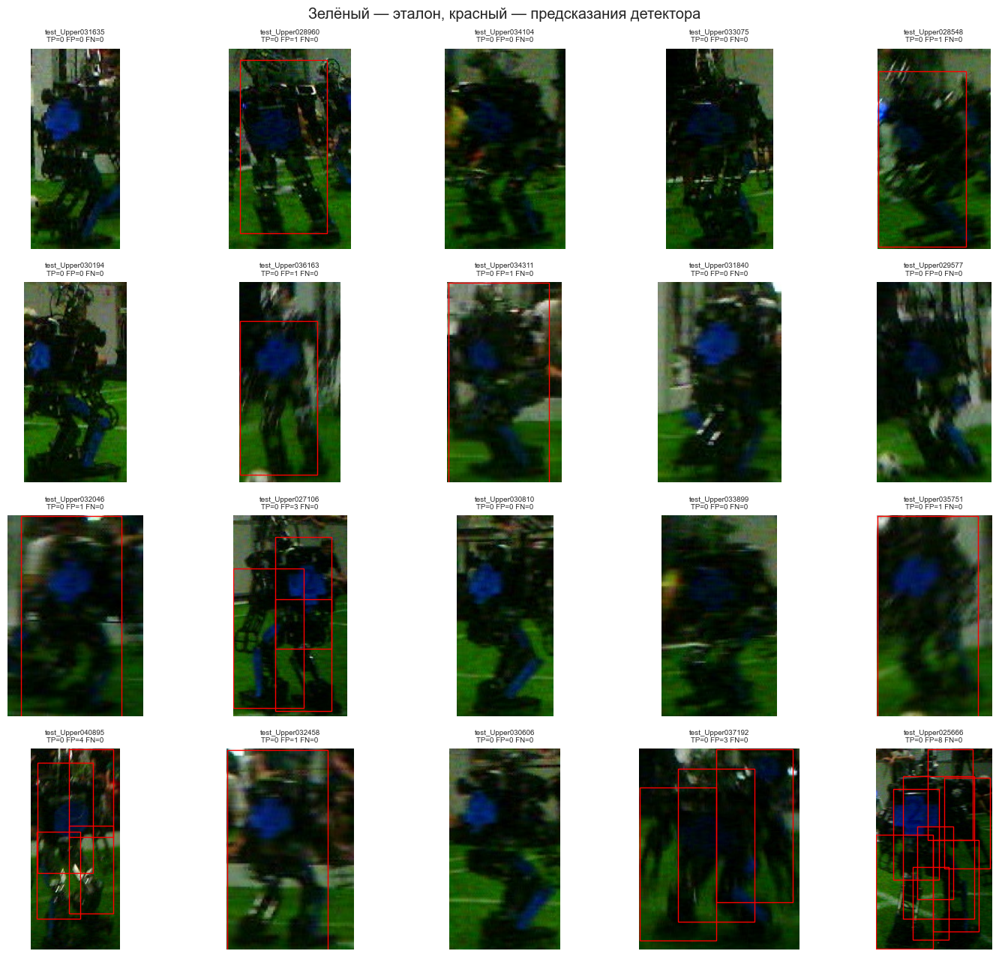

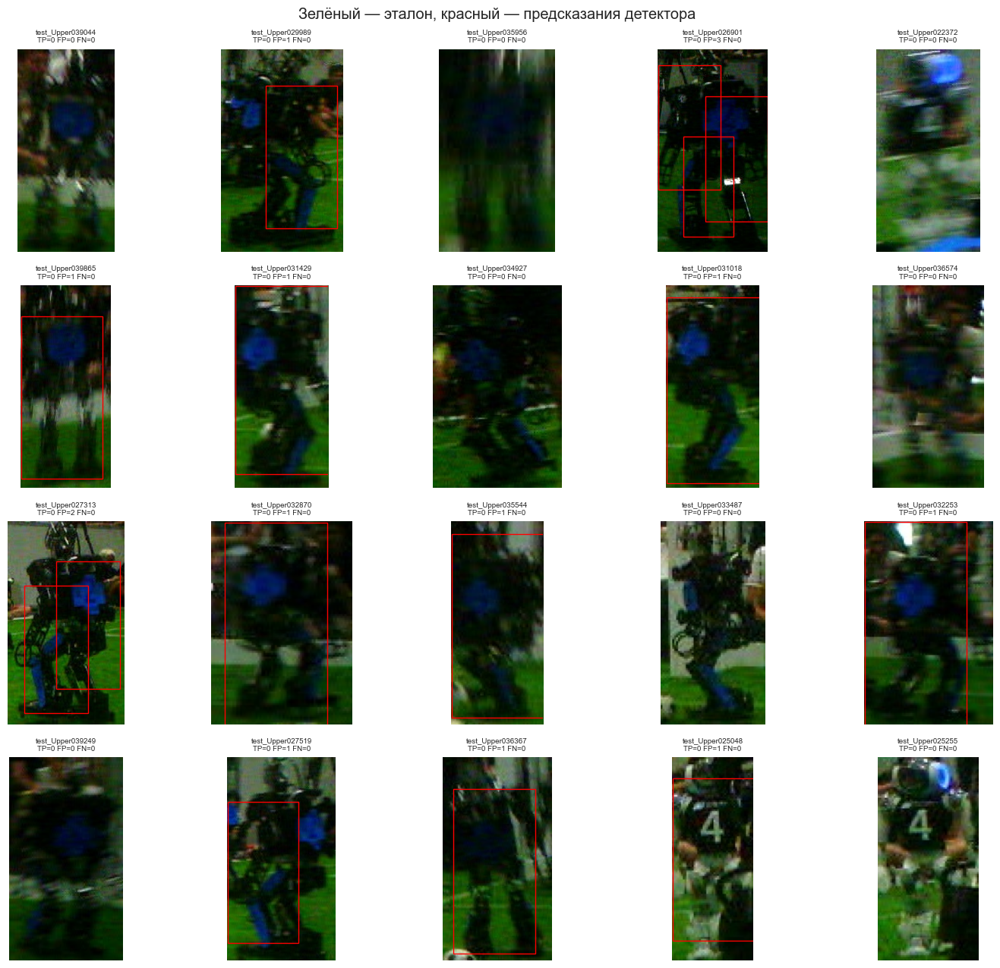

In [5]:
detector,counts=fit_detector([r for r in people if r["split"]=="base"],[r for r in robots if r["split"]=="base"])
print("HOG-окон для обучения детектора по классам:",counts)
detected=[]
for index,row in enumerate(holdout):
    path=row["scene"] if row["label"] else row["crop"]
    boxes,scores=detect(read_photo(path),detector)
    tp,fp,fn,overlaps=match_boxes(row["boxes"] if row["label"] else [],boxes)
    detected.append({"id":row["id"],"image":path,"class":row["label"],"boxes":boxes,"scores":scores,"TP":tp,"FP":fp,"FN":fn,"best_iou":overlaps})
    if (index+1)%10==0:print("Проверено изображений:",index+1)
Path("detector_results.json").write_text(json.dumps(detected,ensure_ascii=False,indent=2),encoding="utf-8")
truth=np.array([r["label"] for r in holdout]);guesses=np.array([bool(r["boxes"]) for r in detected],dtype=int)
tp=sum(r["TP"] for r in detected);fp=sum(r["FP"] for r in detected);fn=sum(r["FN"] for r in detected)
all_iou=[v for row in detected for v in row["best_iou"]]
detector_table=pd.DataFrame([{ "Accuracy наличия":accuracy_score(truth,guesses),"Precision рамок":tp/(tp+fp) if tp+fp else 0,
    "Recall рамок":tp/(tp+fn) if tp+fn else 0,"Средний лучший IoU":np.mean(all_iou),"TP рамок":tp,"FP рамок":fp,"FN рамок":fn}])
display(detector_table.round(3))
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].hist(all_iou,bins=np.linspace(0,1,11));axes[0].axvline(0.5,color="red",linestyle="--")
axes[0].set_title("Лучший IoU для каждого размеченного человека");axes[0].set_xlabel("IoU");axes[0].set_ylabel("число объектов")
ConfusionMatrixDisplay.from_predictions(truth,guesses,ax=axes[1],colorbar=False);axes[1].set_title("Наличие человека на снимке")
plt.tight_layout();plt.show()
display(pd.DataFrame([{k:v for k,v in row.items() if k in ["id","class","TP","FP","FN"]} for row in detected]))

# Все 100 результатов доступны для визуальной проверки, без выбора только удачных.
for start in range(0,100,20):
    fig,axes=plt.subplots(4,5,figsize=(15,13))
    for ax,row,result in zip(axes.flat,holdout[start:start+20],detected[start:start+20]):
        ax.imshow(read_photo(result["image"]));ax.axis("off")
        for box in row["boxes"] if row["label"] else []:
            ax.add_patch(Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],fill=False,edgecolor="lime",linewidth=1))
        for box in result["boxes"]:
            ax.add_patch(Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],fill=False,edgecolor="red",linewidth=1))
        ax.set_title(f'{row["id"][-16:]}\nTP={result["TP"]} FP={result["FP"]} FN={result["FN"]}',fontsize=7)
    fig.suptitle("Зелёный — эталон, красный — предсказания детектора")
    plt.tight_layout();plt.show()

**Интерпретация независимого теста детектора.** Во всех 50 сценах с людьми детектор выдал хотя бы одну рамку; 22 из 50 фотографий гуманоидов он правильно оставил без рамок, а на 28 ошибочно нашёл человека. Отсюда Accuracy наличия объекта = (50 + 22) / 100 = 0.720. Это не означает, что каждый человек на положительной фотографии найден правильно.

По однозначному сопоставлению при IoU ≥ 0.5 получены 107 правильных рамок, 20 пропущенных размеченных людей и 1040 лишних рамок. Recall рамок = 107/127 = 0.843, но Precision = 107/1147 = 0.093. На галереях видно, что красные рамки часто появляются на фасадах, деревьях, фонарях, частях людей и в нескольких масштабах вокруг одного объекта. NMS убирает сильные дубли, но не может устранить разные по положению ложные срабатывания. На тёмных роботах из другого матча тоже возникают ложные детекции. Следовательно, текущий детектор слишком часто принимает фон и человекоподобные контуры за людей.

На гистограмме лучший IoU большинства размеченных объектов находится примерно в диапазоне 0.5–0.8; среднее равно 0.600. Однако для каждого эталона берётся лучшая рамка, поэтому лишние рамки почти не ухудшают этот показатель. Его обязательно нужно читать вместе с низкой Precision. Отсутствующее предсказание даёт IoU = 0, а отрицательные фотографии вообще не включаются в среднее IoU.

**Вывод по детекции.** Схема HOG + линейный SVM действительно реализует поиск положения объекта, но её качество существенно хуже классификации заранее выделенных областей. Выборка для обучения мала, исходные фоны однообразны, часть мелких людей в эталоне не размечена, окно фиксировано по пропорциям, а граница класса обучена на ограниченном наборе отрицательных окон. Результат не является готовым надёжным детектором. Возможное дальнейшее улучшение — сбор сложных отрицательных окон на обучающих сценах и настройка порога на отдельной validation-выборке; в этой работе такой дополнительный эксперимент не выполнялся, и тестовый порог после просмотра результатов не менялся.

## Итоговый вывод

Собраны 300 реальных исходных фотографий: 100 людей и 100 гуманоидов для базовой классификации, а также 50 новых людей и 50 гуманоидов для отдельной проверки детектора. Положительный объект — человек; отрицательный — двуногий робот. В исходной постановке разрешались костюмы роботов, но они не представлены в итоговой исследовательской выборке. Текущие результаты нельзя переносить на всех пришельцев, персонажей и роботов произвольного вида.

Базовая таблица содержит 200 векторов HOG длины 3780 и метки 0/1. На разбиении 80/20 kNN дал Accuracy 85%, а SVM и Logistic Regression — 100%. Визуально разобраны все 40 тестовых изображений и все ошибки kNN. После аугментации только обучающей части kNN улучшился до 92.5%, линейные модели сохранили 100%. Для классификации этого небольшого набора можно выбрать линейный SVM: он делит первое место с Logistic Regression и непосредственно используется в следующей части.

Обучен собственный HOG + линейный SVM-детектор на 100 сценах с людьми, их размеченных объектах и отрицательных обучающих примерах. На независимых 100 фотографиях Accuracy наличия человека составила 72%, средний лучший IoU — 0.600. При этом 1040 лишних рамок и Precision 9.3% показывают серьёзную проблему ложных срабатываний. Проверка локализации необходима: высокая Accuracy на кадрированных объектах не гарантирует качественного поиска рамок в целых сценах.

Сохранены полные таблицы HOG, разделение train/test, эталонные рамки, предсказания для всех 100 изображений и визуальные результаты. В работе выполнены базовая часть, аугментация и детектор с оценкой IoU; показатели приведены без отбора только удачных примеров.